In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, os

# Add the parent directory (project_root) to sys.path
PARENT_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PARENT_DIR not in sys.path:
    sys.path.append(PARENT_DIR)


import numpy as np
import pandas as pd

from gt_concepts.gately_point import exact_gately_value
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split


# Utility wrapper for Gately game (regression, SAME v(S) as least-core)

class _FeatureDataWrapper:
    """Wrapper so exact_gately_point can query feature names / number of players."""
    def __init__(self, feature_names):
        self.data_names = list(feature_names)

    def __len__(self):
        return len(self.data_names)


class RegressionFeatureUtility:
    """
    Cooperative game for regression:
        - Players = features (columns of X)
        - Coalition S (list of indices) = subset of features
        - v(S) = average predicted target when only features in S
                are kept from X_test and others are set to a baseline.
                (Identical v(S) to your least-core & nucleolus regression wrappers.)
    """
    def __init__(self, model, X_train, X_test, feature_names):
        self.model = model
        self.X_train = X_train.reset_index(drop=True)
        self.X_test = X_test.reset_index(drop=True)
        self.feature_names = list(feature_names)
        self.data = _FeatureDataWrapper(self.feature_names)

        # Baseline value for missing features (mean over training data)
        self.baseline = self.X_train.mean(axis=0).values

    def __call__(self, coalition):
        coalition = list(coalition)

        if not coalition:
            # empty coalition = no predictive power
            return 0.0

        # Start from baseline matrix
        X_masked = np.tile(self.baseline, (self.X_test.shape[0], 1))

        # Put back the "active" coalition features from X_test
        X_masked[:, coalition] = self.X_test.iloc[:, coalition].values

        # Predict and take mean prediction as coalition value
        preds = self.model.predict(X_masked)
        return float(preds.mean())


# Gately point attribution for regression

def compute_gately_attribution_reg(model, X_train, X_test, feature_names, solver=None):
    """
    Returns: pd.Series of Gately point attributions for a regression model,
    using the same v(S) as your least-core / nucleolus implementations.
    """
    utility = RegressionFeatureUtility(model, X_train, X_test, feature_names)

    options = {}
    if solver:
        options["solver"] = solver  # e.g. "ECOS", "SCS"

    result = exact_gately_value(utility, options=options)
    return pd.Series(result.values, index=feature_names, name="Gately")


def load_regression_csv(path, target_col=None, test_size=0.25, random_state=42):
    """
    Load a CSV, drop 'Unnamed' index columns, split into train/test.
    If target_col is None, use the last column as target.
    """
    df = pd.read_csv(path)

    # Drop index-like columns such as 'Unnamed: 0'
    df = df.loc[:, ~df.columns.str.contains(r'^Unnamed')]

    if target_col is None:
        target_col = df.columns[-1]

    y = df[target_col].values
    X = df.drop(columns=[target_col])

    feature_names = list(X.columns)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    return X_train, X_test, y_train, y_test, feature_names


def run_gately_on_csv(path, target_col, dataset_name):
    print("\n" + "=" * 72)
    print(f"Gately Point (regression) on: {dataset_name}")
    print("=" * 72)

    X_train, X_test, y_train, y_test, feature_names = load_regression_csv(
        path, target_col=target_col
    )

    # Train regression model (same as for least-core & nucleolus)
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        random_state=42,
    )
    model.fit(X_train, y_train)

    # Compute Gately attributions
    gately_values = compute_gately_attribution_reg(
        model,
        X_train,
        X_test,
        feature_names,
        solver=None,
    )

    print("\n===== Gately Point Attributions =====")
    print(gately_values.sort_values(ascending=False))
    return gately_values


if __name__ == "__main__":
    LUNG_PATH = "../datasets/lung_cancer_risk.csv"
    CV_PATH   = "../datasets/cv_risk.csv"

    # Lung cancer: target column is 'lung_cancer_risk'
    lung_gately = run_gately_on_csv(
        LUNG_PATH,
        target_col="lung_cancer_risk",
        dataset_name="synthetic_lung_cancer_risk",
    )

    # Cardiovascular risk: target column is 'cv_risk'
    cv_gately = run_gately_on_csv(
        CV_PATH,
        target_col="cv_risk",
        dataset_name="synthetic_cardiovascular_risk",
    )


Gately Point (regression) on: synthetic_lung_cancer_risk

===== Gately Point Attributions =====
stress          5.446301
drink_coffee    5.411345
smoking         5.130103
Name: Gately, dtype: float64

Gately Point (regression) on: synthetic_cardiovascular_risk

===== Gately Point Attributions =====
family_history    2.902848
diet_score        2.886102
sleep_duration    2.836856
bmi               2.547235
Name: Gately, dtype: float64


In [2]:
lung_gately = pd.Series(
    {"stress": 5.446493, "drink_coffee": 5.409706, "smoking": 5.130992},
    name="Gately"
)

cv_gately = pd.Series(
    {
        "family_history": 2.902115,
        "diet_score": 2.887186,
        "sleep_duration": 2.836650,
        "bmi": 2.547280
    },
    name="Gately"
)

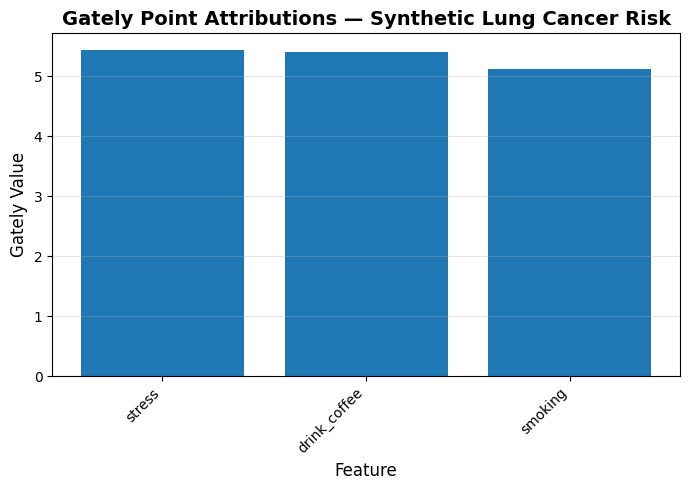

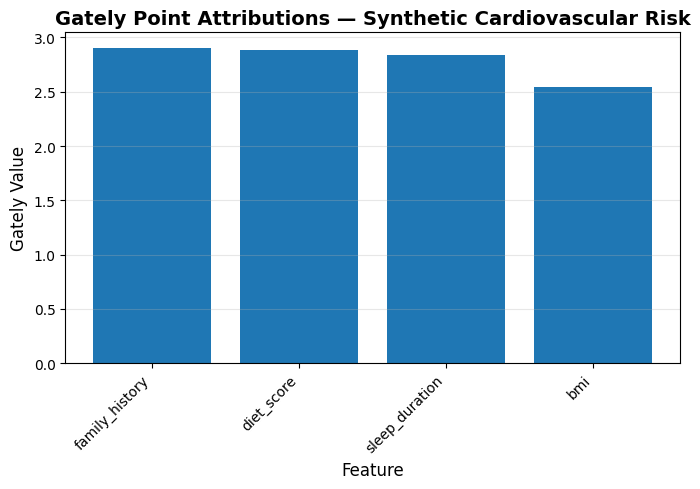

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_gately_vertical(gately_series, title, filename=None):
    """
    gately_series: pd.Series (index = feature names, values = Gately scores)
    Creates a vertical bar plot.
    """
    s = gately_series.sort_values(ascending=False)

    plt.figure(figsize=(7, 5))
    plt.bar(s.index, s.values)
    plt.ylabel("Gately Value", fontsize=12)
    plt.xlabel("Feature", fontsize=12)
    plt.title(title, fontsize=14, fontweight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    if filename:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()


plot_gately_vertical(
    lung_gately,
    title="Gately Point Attributions — Synthetic Lung Cancer Risk",
    filename="gately_lung_vertical.png"
)

plot_gately_vertical(
    cv_gately,
    title="Gately Point Attributions — Synthetic Cardiovascular Risk",
    filename="gately_cv_vertical.png"
)